# Regresión y evaluación temporal
Entrenamos con 2015–2018 (626 filas) y evaluamos con 2019 (156). La división temporal sustituye la sugerencia 70/30 para representar la aplicación a un año posterior. País y año se conservan para trazabilidad, no se usan como predictores.

In [1]:
from pathlib import Path
import sys
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from src.config import FEATURES
from src.data import load_data, ALIASES
sns.set_theme(style='whitegrid', palette='viridis')


## Pipeline reproducible
Imputación por mediana → estandarización → regresión lineal. Todo el preprocesamiento se ajusta en entrenamiento y se serializa con el estimador. El puntaje real solo se usa como objetivo/evaluación. No usamos rango, residual ni intervalos del puntaje.

In [2]:
from src.train import train
model, metadata = train()
display(pd.Series(metadata['metrics'],name='test_2019'))
print('Filas de entrenamiento:',metadata['train_rows'])
print('Filas de prueba:',metadata['test_rows'])

{
  "features": [
    "gdp",
    "family",
    "health",
    "freedom",
    "generosity",
    "corruption"
  ],
  "train_years": [
    2015,
    2016,
    2017,
    2018
  ],
  "test_years": [
    2019
  ],
  "train_rows": 626,
  "test_rows": 156,
  "metrics": {
    "mae": 0.42420889094311465,
    "rmse": 0.5496792180531228,
    "r2": 0.7545699894821631
  },
  "sklearn_version": "1.9.1",
  "model_sha256": "3c0594580177472bf9d368f1d532c9b73eae5fdb01f72a71143f572ea3bf6946"
}


mae     0.424209
rmse    0.549679
r2      0.754570
Name: test_2019, dtype: float64

Filas de entrenamiento: 626
Filas de prueba: 156


In [3]:
data=load_data()
train_data=data[data.year<2019]
test_data=data[data.year==2019]
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
baseline=[train_data.happiness_score.mean()]*len(test_data)
display(pd.DataFrame([{'model':'Media de entrenamiento','mae':mean_absolute_error(test_data.happiness_score,baseline),'rmse':root_mean_squared_error(test_data.happiness_score,baseline),'r2':r2_score(test_data.happiness_score,baseline)},{'model':'Regresión lineal',**metadata['metrics']}]))

,model,mae,rmse,r2
0,Media de entrenamiento,0.916391,1.110101,-0.000999
1,Regresión lineal,0.424209,0.549679,0.754570


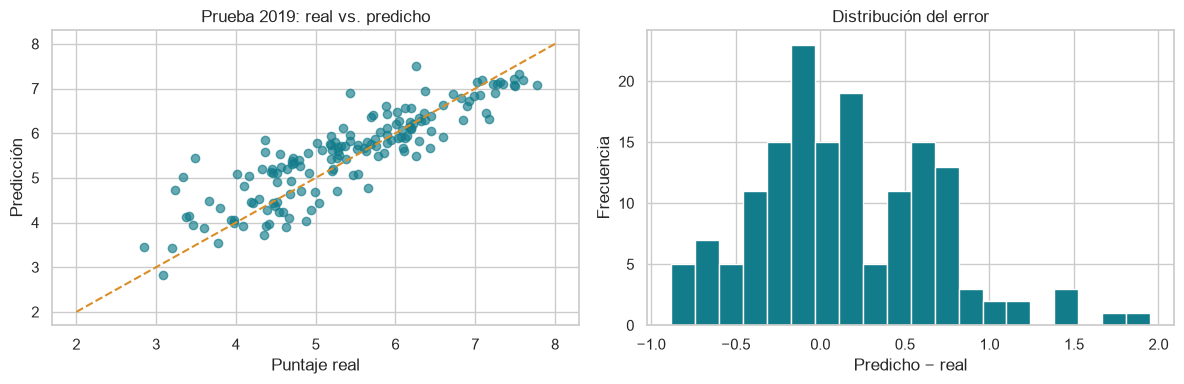

gdp           0.451116
family        0.210117
health        0.275726
freedom       0.218107
generosity    0.068665
corruption    0.093132
Name: Coeficiente estandarizado, dtype: float64

In [4]:
pred=model.predict(test_data[FEATURES])
fig, axes=plt.subplots(1,2,figsize=(12,4))
axes[0].scatter(test_data.happiness_score,pred,alpha=.65,color='#137C8B')
axes[0].plot([2,8],[2,8],'--',color='#DB8E26')
axes[0].set(xlabel='Puntaje real',ylabel='Predicción',title='Prueba 2019: real vs. predicho')
axes[1].hist(pred-test_data.happiness_score,bins=20,color='#137C8B')
axes[1].set(xlabel='Predicho − real',ylabel='Frecuencia',title='Distribución del error')
plt.tight_layout()
plt.show()
display(pd.Series(model.named_steps['regressor'].coef_,index=FEATURES,name='Coeficiente estandarizado'))

## Interpretación y límites
MAE y RMSE se expresan en puntos del puntaje; valores menores son mejores. R² compara con la media del conjunto evaluado y puede ser negativo. Los coeficientes no demuestran causalidad. Son pocos años, las ediciones cambian y los mismos países aparecen en entrenamiento/prueba; el resultado representa otro año de países conocidos, no una garantía para países nuevos. Las métricas del dashboard para todos los años incluyen entrenamiento: filtrar `evaluation_split=test` para evaluar generalización.

In [5]:
import pickle
import numpy as np
restored=pickle.loads((ROOT/'models/model.pkl').read_bytes())
np.testing.assert_allclose(restored.predict(test_data[FEATURES]),pred)
assert list(restored.feature_names_in_)==FEATURES
print('Serialización y orden de características verificados.')

Serialización y orden de características verificados.
